In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Aufgabe 1: Bestimmung der Tonhöhe eines akustischen Signals

Einlesen der Messdaten

In [3]:
data = pd.read_csv(
    "data/ton2.csv",
    sep=";",
    decimal=",",
    skiprows=3,
    header=None
)

zeit = data[0].to_numpy()
signal = data[1].to_numpy()

print(data.head())

           0         1
0 -25.007999  2.426796
1 -25.002999  2.053396
2 -24.997999  2.426796
3 -24.992999  1.492987
4 -24.987999  1.679995


### Graphische Darstellung des Signals

Das aufgenommene Signal wird im Zeitbereich dargestellt.

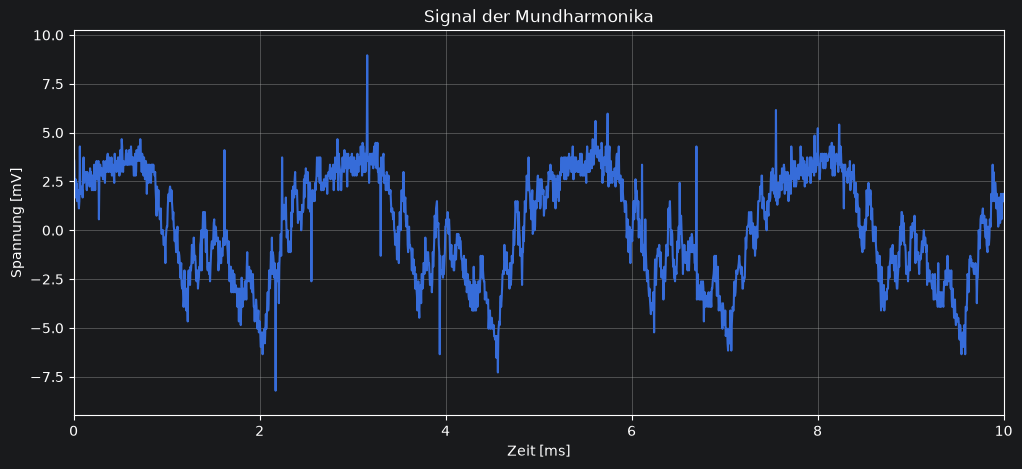

In [4]:
plt.figure(figsize=(12, 5))

plt.plot(zeit, signal)

plt.xlabel("Zeit [ms]")
plt.ylabel("Spannung [mV]")
plt.title("Signal der Mundharmonika")
plt.grid()
plt.xlim(0, 10)
plt.show()

### Bestimmung der Grundperiode und Grundfrequenz


In [5]:
# Grundperiode in Sekunden
T0 = 2.5 / 1000

# Grundfrequenz
f0 = 1 / T0

print("Grundperiode:", T0 * 1000, "ms")
print("Grundfrequenz:", f0, "Hz")

Grundperiode: 2.5 ms
Grundfrequenz: 400.0 Hz


### Bestimmung der Signalparameter

Es werden die Signallänge M, das Abtastintervall,
die Abtastfrequenz und die Signaldauer bestimmt.

In [6]:
# Signallänge
M = len(signal)

# Abtastintervall in Sekunden
dt = np.mean(np.diff(zeit)) / 1000

# Abtastfrequenz
fs = 1 / dt

# Signaldauer
T = M * dt

print("Signallänge:", M)
print("Abtastintervall:", dt, "s")
print("Abtastfrequenz:", fs, "Hz")
print("Signaldauer:", T, "s")

Signallänge: 10004
Abtastintervall: 4.999999873038088e-06 s
Abtastfrequenz: 200000.00507847662 Hz
Signaldauer: 0.05001999872987303 s


### Fouriertransformation und Amplitudenspektrum

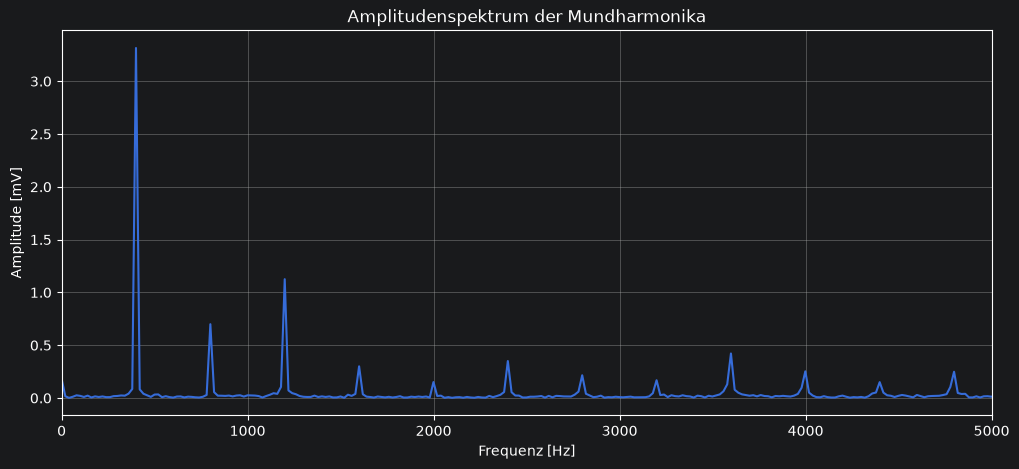

In [7]:
# Fouriertransformation
fourier = np.fft.fft(signal)

# Einseitiges Amplitudenspektrum
amplitude = 2 / M * np.abs(fourier[:(M + 1) // 2])
amplitude[0] /= 2

# Frequenzachse in Hertz
frequenz = np.arange(len(amplitude)) / (M * dt)

plt.figure(figsize=(12, 5))

plt.plot(frequenz, amplitude)
plt.xlabel("Frequenz [Hz]")
plt.ylabel("Amplitude [mV]")
plt.title("Amplitudenspektrum der Mundharmonika")
plt.grid()
plt.xlim(0, 5000)
plt.show()

### Bestimmung der Grundfrequenz im Spektrum

Die Grundfrequenz wird im Amplitudenspektrum
identifiziert. Anschließend werden ihre Frequenz
und Amplitude bestimmt.

In [8]:
# Index der maximalen Amplitude (ohne Gleichanteil)
index = np.argmax(amplitude[1:]) + 1

# Dominante Frequenz und Amplitude
f0_fft = frequenz[index]
A0 = amplitude[index]

print("Frequenz:", f0_fft, "Hz")
print("Amplitude:", A0, "mV")

Frequenz: 399.8400741273023 Hz
Amplitude: 3.314505609656183 mV


## AUFGABE 2
### Darstellung des Sprachsignals

Als Sprachsignal wurde das russische Wort
„Privet“ (Hallo) aufgenommen.

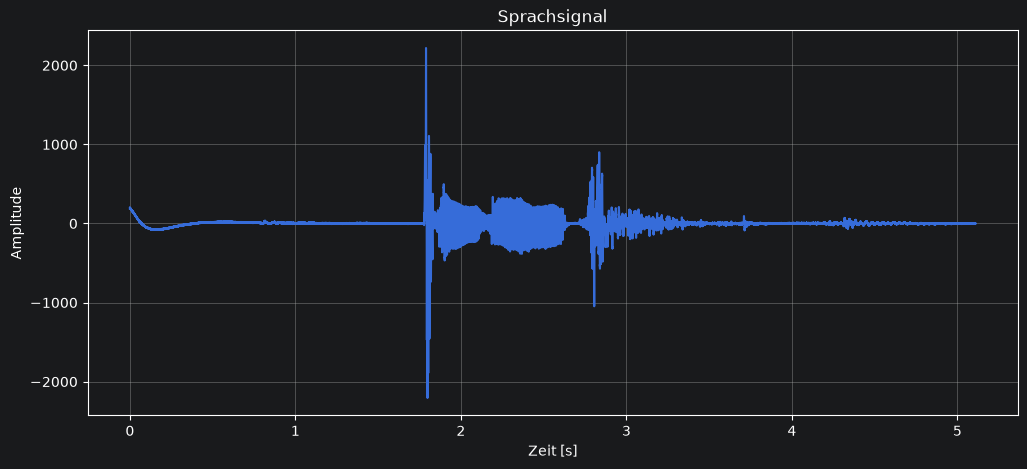

In [9]:
audio = np.load("data/audio.npy")

fs_audio = 44100
zeit_audio = np.arange(len(audio)) / fs_audio

plt.figure(figsize=(12, 5))
plt.plot(zeit_audio, audio)

plt.xlabel("Zeit [s]")
plt.ylabel("Amplitude")
plt.title("Sprachsignal")
plt.grid()
plt.show()

### Aufgabe 2b: Triggerfunktion

Der Beginn des Sprachsignals wird mithilfe
eines Schwellenwertes automatisch bestimmt.

In [10]:
def trigger(signal, fs, schwelle=300):
    start = np.where(np.abs(signal.astype(float)) > schwelle)[0][0]

    signal = signal[start:start + fs]

    if len(signal) < fs:
        signal = np.pad(signal, (0, fs - len(signal)))

    return signal


audio_trigger = trigger(audio, fs_audio)

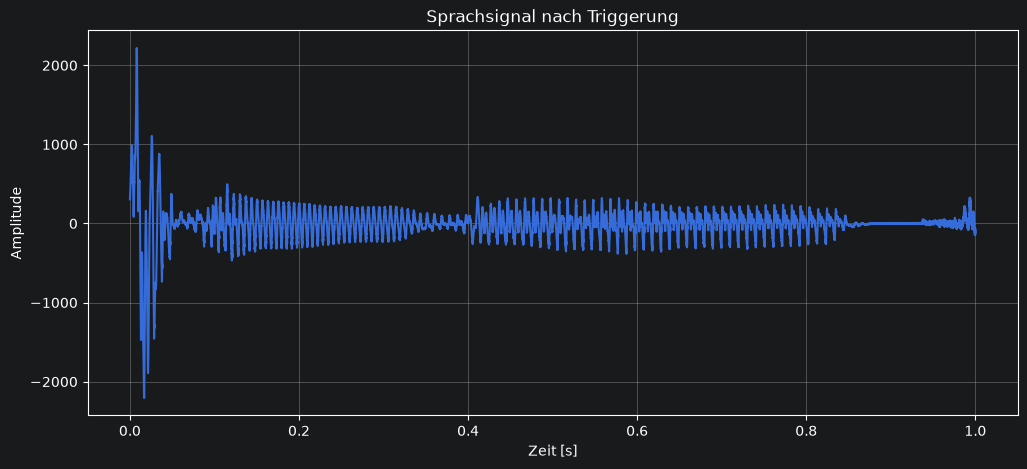

Signallänge: 44100
Signaldauer: 1.0 s


In [11]:
zeit_trigger = np.arange(len(audio_trigger)) / fs_audio

plt.figure(figsize=(12, 5))
plt.plot(zeit_trigger, audio_trigger)

plt.xlabel("Zeit [s]")
plt.ylabel("Amplitude")
plt.title("Sprachsignal nach Triggerung")
plt.grid()
plt.show()

print("Signallänge:", len(audio_trigger))
print("Signaldauer:", len(audio_trigger) / fs_audio, "s")

### Aufgabe 2c: Amplitudenspektrum

Mithilfe der diskreten Fouriertransformation
wird das Amplitudenspektrum des getriggerten
Sprachsignals berechnet und dargestellt.

In [13]:
M_audio = len(audio_trigger)
dt_audio = 1 / fs_audio

fourier_audio = np.fft.fft(audio_trigger)

amplitude_audio = 2 / M_audio * np.abs(
    fourier_audio[:M_audio // 2 + 1]
)

amplitude_audio[0] /= 2
amplitude_audio[-1] /= 2

frequenz_audio = np.arange(len(amplitude_audio)) / (
    M_audio * dt_audio
)

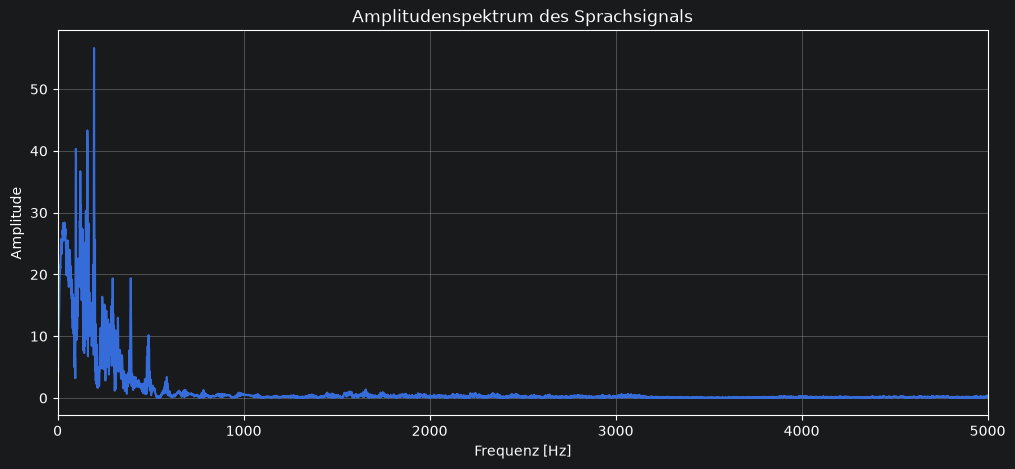

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(frequenz_audio, amplitude_audio)

plt.xlabel("Frequenz [Hz]")
plt.ylabel("Amplitude")
plt.title("Amplitudenspektrum des Sprachsignals")

plt.xlim(0, 5000)
plt.grid()
plt.show()

### Aufgabe 2d: Windowing

Das Sprachsignal wird in Fenster mit einer Länge
von 512 Samples und einer Überlappung von 50 %
unterteilt.

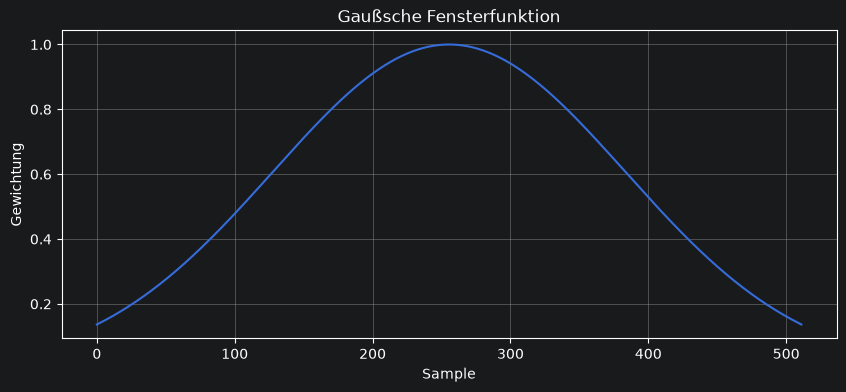

In [15]:
N = 512
step = N // 2
sigma = N / 4

n = np.arange(N)

gauss = np.exp(-0.5 * ((n - (N - 1) / 2) / sigma)**2)

plt.figure(figsize=(10, 4))
plt.plot(n, gauss)

plt.xlabel("Sample")
plt.ylabel("Gewichtung")
plt.title("Gaußsche Fensterfunktion")
plt.grid()
plt.show()

In [16]:
def windowing(signal, fs):
    leistungsspektren = []

    for start in range(0, len(signal) - N + 1, step):
        fenster = signal[start:start + N]

        fenster = fenster * gauss

        fourier = np.fft.fft(fenster)

        amplitude = 2 / np.sum(gauss) * np.abs(
            fourier[:N // 2 + 1]
        )

        amplitude[0] /= 2
        amplitude[-1] /= 2

        leistung = amplitude**2

        leistungsspektren.append(leistung)

    mittlere_leistung = np.mean(leistungsspektren, axis=0)

    amplitude = np.sqrt(mittlere_leistung)

    frequenz = np.arange(len(amplitude)) * fs / N

    return frequenz, amplitude

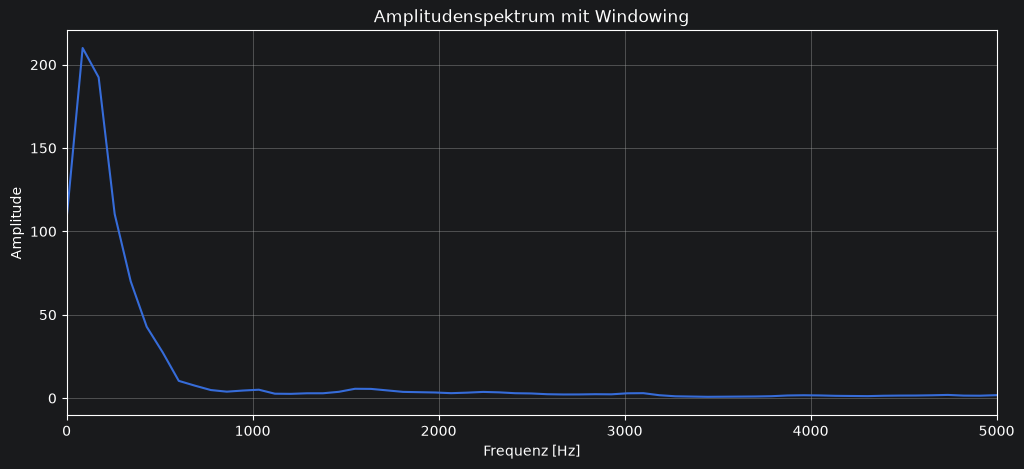

In [17]:
frequenz_window, amplitude_window = windowing(
    audio_trigger, fs_audio
)

plt.figure(figsize=(12, 5))

plt.plot(frequenz_window, amplitude_window)

plt.xlabel("Frequenz [Hz]")
plt.ylabel("Amplitude")
plt.title("Amplitudenspektrum mit Windowing")

plt.xlim(0, 5000)
plt.grid()
plt.show()

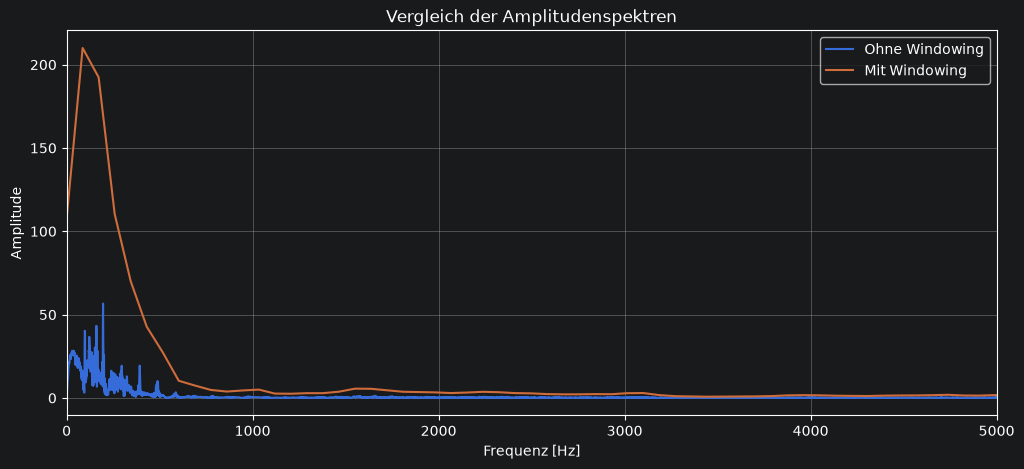

In [18]:
plt.figure(figsize=(12, 5))

plt.plot(frequenz_audio, amplitude_audio,
         label="Ohne Windowing")

plt.plot(frequenz_window, amplitude_window,
         label="Mit Windowing")

plt.xlabel("Frequenz [Hz]")
plt.ylabel("Amplitude")
plt.title("Vergleich der Amplitudenspektren")

plt.xlim(0, 5000)
plt.legend()
plt.grid()
plt.show()